In [3]:
import pandas as pd
import re

#Who communicates the most?
#When is the group most active?
#How verbose is each participant?
#What topics dominate the conversation?
#What emotions are expressed?
#How do communication patterns change over time?

# ***1. Data Processing***

# 1.1 Read whatsapp chat

In [2]:
file_path="whatsapp_chat.txt"

with open(file_path,"r",encoding="utf-8") as file:
    data=file.readlines()

print(data[:10])




['23/11/2025, 10:46 - Messages and calls are end-to-end encrypted. Only people in this chat can read, listen to, or share them. *Learn more*\n', '05/09/2025, 19:35 - Manya MIT created group "Skribbl grp"\n', '05/09/2025, 19:35 - You were added\n', '23/11/2025, 15:27 - abhijna: \n', '23/11/2025, 15:27 - abhijna: Hey anyone pls send da formula book I have lost everything 😭\n', '23/11/2025, 15:30 - Manya MIT: <Media omitted>\n', '23/11/2025, 15:39 - abhijna: Thankyou\n', '23/11/2025, 17:35 - Sohail MIT: <Media omitted>\n', '23/11/2025, 17:37 - Sohail MIT: <Media omitted>\n', "23/11/2025, 17:37 - abhijna: Sorry bro can't relate\n"]


In [3]:
print(data[0])
print(data[1])
print(data[2])

23/11/2025, 10:46 - Messages and calls are end-to-end encrypted. Only people in this chat can read, listen to, or share them. *Learn more*

05/09/2025, 19:35 - Manya MIT created group "Skribbl grp"

05/09/2025, 19:35 - You were added



# 1.2 Regex parsing

In [4]:
pattern=r"(\d{1,2}/\d{1,2}/\d{2,4}),\s(\d{1,2}:\d{2})\s-\s([^:]+):\s(.*)"

dates=[]
times=[]
users=[]
messages=[]

for line in data:

    match=re.match(pattern,line)

    if match:
        dates.append(match.group(1))
        times.append(match.group(2))
        users.append(match.group(3))
        messages.append(match.group(4))



print(dates[:5])
print(times[:5])
print(users[:5])
print(messages[:5])
    

['23/11/2025', '23/11/2025', '23/11/2025', '23/11/2025', '23/11/2025']
['15:27', '15:27', '15:30', '15:39', '17:35']
['abhijna', 'abhijna', 'Manya MIT', 'abhijna', 'Sohail MIT']
['', 'Hey anyone pls send da formula book I have lost everything 😭', '<Media omitted>', 'Thankyou', '<Media omitted>']


# 1.3 Create Dataframe

In [5]:
df=pd.DataFrame({
    "Date":dates,
    "Time":times,
    "User":users,
    "Message":messages
})


print(df.head())
df[["User","Time"]]

df.shape


         Date   Time        User  \
0  23/11/2025  15:27     abhijna   
1  23/11/2025  15:27     abhijna   
2  23/11/2025  15:30   Manya MIT   
3  23/11/2025  15:39     abhijna   
4  23/11/2025  17:35  Sohail MIT   

                                             Message  
0                                                     
1  Hey anyone pls send da formula book I have los...  
2                                    <Media omitted>  
3                                           Thankyou  
4                                    <Media omitted>  


(7402, 4)

In [6]:
unique_users = df["User"].unique()

user_mapping = {}

for i, user in enumerate(unique_users, start=1):
    user_mapping[user] = f"User{i}"

print(user_mapping)

df["Anonymous_User"] = df["User"].map(user_mapping)

{'abhijna': 'User1', 'Manya MIT': 'User2', 'Sohail MIT': 'User3', 'Varsha MIT': 'User4', 'Vibha Bhat MIT': 'User5', 'Meta AI': 'User6'}


# 1.4 Feature Engineering

In [7]:
df["DateTime"]=pd.to_datetime(
    df["Date"]+ " "+ df["Time"],dayfirst=True
)
df['Year']=df['DateTime'].dt.year
df['Month']=df['DateTime'].dt.month
df['Day']=df['DateTime'].dt.day
df['Hour']=df['DateTime'].dt.hour
df['Week_day']=df['DateTime'].dt.day_name()
df['Month name']=df['DateTime'].dt.month_name()
text_df=df[df['Message']!="<Media omitted>"]
text_df = df[df["Message"] != "This message was deleted"]
text_df = df[df["Message"].str.strip() != ""]

df.head()
df.shape

(7402, 12)

# ***2. Basic Analytics***

<Axes: xlabel='Hour'>

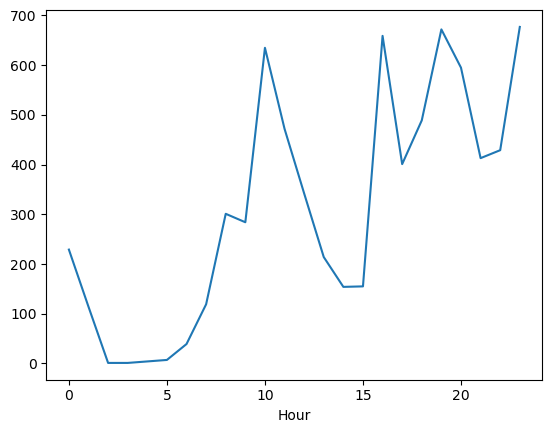

In [8]:
df['Hour'].value_counts().sort_index().plot(kind="line") #communication times

<Axes: xlabel='Month name'>

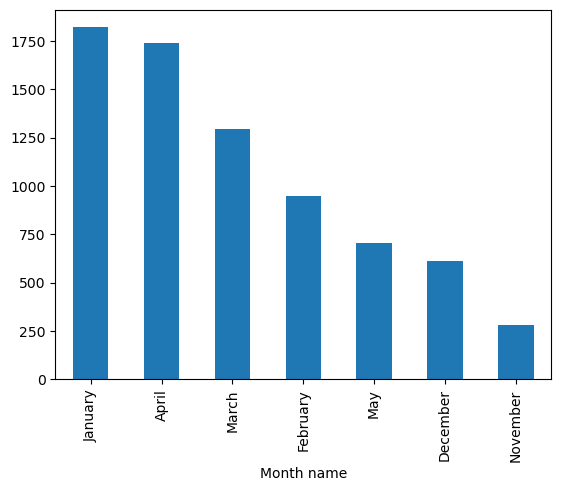

In [9]:
df['Month name'].value_counts().plot(kind='bar')

In [10]:
df['MessageLength']=df['Message'].str.len()
df[['Message','MessageLength']].head(10)

,Message,MessageLength
0,,0
1,Hey anyone pls send da formula book I have los...,60
2,<Media omitted>,15
3,Thankyou,8
4,<Media omitted>,15
5,<Media omitted>,15
6,Sorry bro can't relate,22
7,Coz I did,9
8,You guys knew the whole time 😭😭😭,32
9,And no one cared to tell me,27


In [11]:
df['MessageLength'].describe()

count    7402.000000
mean       23.200486
std        22.042332
min         0.000000
25%         9.000000
50%        17.000000
75%        31.000000
max       411.000000
Name: MessageLength, dtype: float64

In [12]:
df.groupby('Anonymous_User')['MessageLength'].mean().sort_values(ascending=False)
#writes the longest message(with message length)

Anonymous_User
User6    73.692308
User5    33.392929
User3    26.211503
User4    24.141289
User1    22.906564
User2    15.294277
Name: MessageLength, dtype: float64

In [13]:
df["WordCount"] = df["Message"].apply(lambda x: len(x.split()))

df[["Message", "WordCount"]].head()

,Message,WordCount
0,,0
1,Hey anyone pls send da formula book I have los...,12
2,<Media omitted>,2
3,Thankyou,1
4,<Media omitted>,2


In [14]:
df['WordCount'].describe()

count    7402.000000
mean        4.437584
std         3.963379
min         0.000000
25%         2.000000
50%         3.000000
75%         6.000000
max        63.000000
Name: WordCount, dtype: float64

In [15]:
df.groupby('Anonymous_User')['WordCount'].mean().sort_values(ascending=False)
#User with longest messege by (Words)

Anonymous_User
User6    13.461538
User5     6.639394
User4     4.539095
User3     4.521800
User1     4.329730
User2     3.350158
Name: WordCount, dtype: float64

In [16]:
!pip install nltk

In [17]:
import nltk
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\User\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [18]:
from nltk.corpus import stopwords

stop_words=set(stopwords.words('english'))
print(list(stop_words)[:2000])

['have', "he'll", 'off', 'their', 'ours', 'when', 'out', 'should', 'other', 'all', 'how', "she'll", 'was', 'she', 'hasn', 'below', "she's", 'themselves', 'where', 'while', 'his', "hadn't", 'we', 'this', 'been', "wasn't", 'here', "couldn't", 'such', 't', 'about', 'nor', "mightn't", 'these', "haven't", 'y', 'most', 'them', 'does', 'not', 'there', "they'll", 'after', "i'll", 'which', 'it', 'through', 'against', 'just', 'by', 'yours', "aren't", "shouldn't", "you've", 'over', 'if', 'you', 're', 'to', 'what', 'your', 'same', 'or', 'down', 'from', 'him', 'needn', 'o', "should've", 'into', 'hadn', 'am', "he'd", 'ourselves', 'than', "wouldn't", 'an', "you're", 'yourself', "i'd", 'both', 'very', 'each', "it's", 'me', 'on', 'once', "it'd", "he's", 'shouldn', 'again', 'then', 've', 'doing', 'between', 'hers', 'at', "it'll", 'only', 'few', 'doesn', 'its', 'of', 'm', 'now', 'under', 'will', 'd', 'as', 'll', 'ain', 'can', 'my', 'ma', 'they', 'too', "they've", "they'd", 'because', 'why', "we're", 'for

In [19]:
all_messages="  ".join(df['Message'])
all_messages=all_messages.lower()
print(all_messages[:200])
print()

words=all_messages.split()
print(words[:30])
print()

filtered_words=[]

for word in words:
    if word not in stop_words:
        filtered_words.append(word)

print(filtered_words[:30])

  hey anyone pls send da formula book i have lost everything 😭  <media omitted>  thankyou  <media omitted>  <media omitted>  sorry bro can't relate  coz i did  you guys knew the whole time 😭😭😭  and no

['hey', 'anyone', 'pls', 'send', 'da', 'formula', 'book', 'i', 'have', 'lost', 'everything', '😭', '<media', 'omitted>', 'thankyou', '<media', 'omitted>', '<media', 'omitted>', 'sorry', 'bro', "can't", 'relate', 'coz', 'i', 'did', 'you', 'guys', 'knew', 'the']

['hey', 'anyone', 'pls', 'send', 'da', 'formula', 'book', 'lost', 'everything', '😭', '<media', 'omitted>', 'thankyou', '<media', 'omitted>', '<media', 'omitted>', 'sorry', 'bro', "can't", 'relate', 'coz', 'guys', 'knew', 'whole', 'time', '😭😭😭', 'one', 'cared', 'tell']


In [20]:
from collections import Counter

word_count=Counter(filtered_words)
word_count.most_common(20)

[('<media', 449),
 ('omitted>', 449),
 ('u', 443),
 ('guys', 206),
 ('bro', 167),
 ('message', 154),
 ('also', 129),
 ('yes', 129),
 ('come', 128),
 ('know', 124),
 ('go', 120),
 ('like', 119),
 ('mit\u2069', 117),
 ('even', 116),
 ('class', 109),
 ('ppl', 103),
 ('one', 102),
 ('man', 99),
 ('see', 95),
 ('<this', 92)]

In [21]:
import string

cleaned_words=[]

for  word in filtered_words:
    word=word.translate(str.maketrans('','',string.punctuation))

    if word!="":
        cleaned_words.append(word)

word_count=Counter(cleaned_words)
word_count.most_common(20)



[('media', 450),
 ('omitted', 449),
 ('u', 447),
 ('guys', 214),
 ('bro', 180),
 ('message', 154),
 ('come', 136),
 ('know', 133),
 ('yes', 133),
 ('also', 129),
 ('go', 124),
 ('like', 121),
 ('class', 120),
 ('even', 117),
 ('mit\u2069', 117),
 ('ppl', 106),
 ('man', 105),
 ('one', 103),
 ('this', 101),
 ('see', 97)]

In [22]:
custom_stopwords = {
    "media", "omitted", "message", "deleted",
    "https", "http", "www", "com",
    "img", "jpg", "png", "gif",
    "sticker", "video", "audio", "document"
}

final_words=[]

for word in cleaned_words:
    if word not in custom_stopwords:
        final_words.append(word)

print(final_words[:20])

['hey', 'anyone', 'pls', 'send', 'da', 'formula', 'book', 'lost', 'everything', '😭', 'thankyou', 'sorry', 'bro', 'cant', 'relate', 'coz', 'guys', 'knew', 'whole', 'time']


# Top Words

[('media', 450), ('omitted', 449), ('u', 447), ('guys', 214), ('bro', 180), ('message', 154), ('come', 136), ('know', 133), ('yes', 133), ('also', 129), ('go', 124), ('like', 121), ('class', 120), ('even', 117), ('mit\u2069', 117), ('ppl', 106), ('man', 105), ('one', 103), ('this', 101), ('see', 97)]
['media', 'omitted', 'u', 'guys', 'bro', 'message', 'come', 'know', 'yes', 'also', 'go', 'like', 'class', 'even', 'mit\u2069', 'ppl', 'man', 'one', 'this', 'see']
[450, 449, 447, 214, 180, 154, 136, 133, 133, 129, 124, 121, 120, 117, 117, 106, 105, 103, 101, 97]


D:\Downloads\jupyter\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8297 (\N{POP DIRECTIONAL ISOLATE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


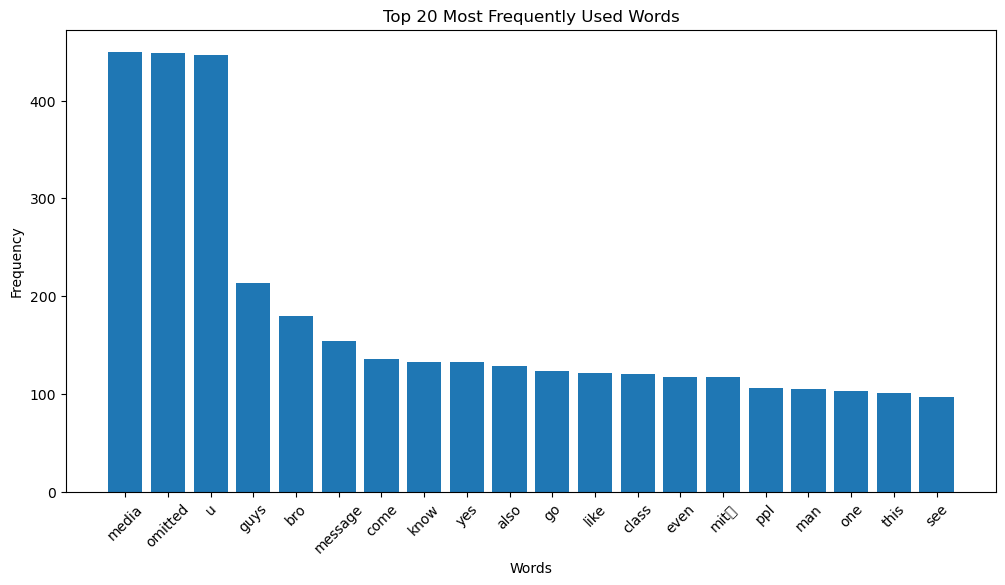

In [23]:
#top 20 Words

import matplotlib.pyplot as plt
top_words=word_count.most_common(20)
print(top_words)

words = []
counts = []

for word, count in top_words:
    words.append(word)
    counts.append(count)

print(words)
print(counts)


plt.figure(figsize=(12,6))

plt.bar(words, counts)

plt.title("Top 20 Most Frequently Used Words")

plt.xlabel("Words")

plt.ylabel("Frequency")

plt.xticks(rotation=45)

plt.show()

# Emoji Analysis

In [24]:
!pip install emoji

In [25]:
import emoji
from collections import Counter

In [26]:
emoji_list=[]

for message in df['Message']:
    for char in message:
        if char in emoji.EMOJI_DATA:
            emoji_list.append(char)

print(emoji_list[:20])

emoji_count=Counter(emoji_list)
emoji_count.most_common(10)

['😭', '😭', '😭', '😭', '😈', '😈', '😭', '😭', '😭', '😭', '😭', '😭', '😭', '😭', '😭', '😭', '😭', '😭', '😭', '😭']


[('😭', 226),
 ('😂', 191),
 ('🙏', 90),
 ('😔', 19),
 ('🥳', 16),
 ('🤣', 15),
 ('🔥', 14),
 ('🏻', 13),
 ('🤯', 12),
 ('🥲', 12)]

In [27]:
# Dataframe of emojis (instead of printing the tuples)

emoji_df=pd.DataFrame(
    emoji_count.most_common(20),
    columns=['Emoji','Count']
)
emoji_df

#Even without reading the messages, you can infer that the emotional tone of the groups can be determined

,Emoji,Count
0,😭,226
1,😂,191
2,🙏,90
3,😔,19
4,🥳,16
5,🤣,15
6,🔥,14
7,🏻,13
8,🤯,12
9,🥲,12


D:\Downloads\jupyter\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 128591 (\N{PERSON WITH FOLDED HANDS}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
D:\Downloads\jupyter\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 129395 (\N{FACE WITH PARTY HORN AND PARTY HAT}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
D:\Downloads\jupyter\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 129315 (\N{ROLLING ON THE FLOOR LAUGHING}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
D:\Downloads\jupyter\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 128293 (\N{FIRE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
D:\Downloads\jupyter\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 127995 (\N{EMOJI MODIFIER FITZPATRICK TYPE-1-2}) missing from font(s) DejaVu Sans.
  fig.canvas.pri

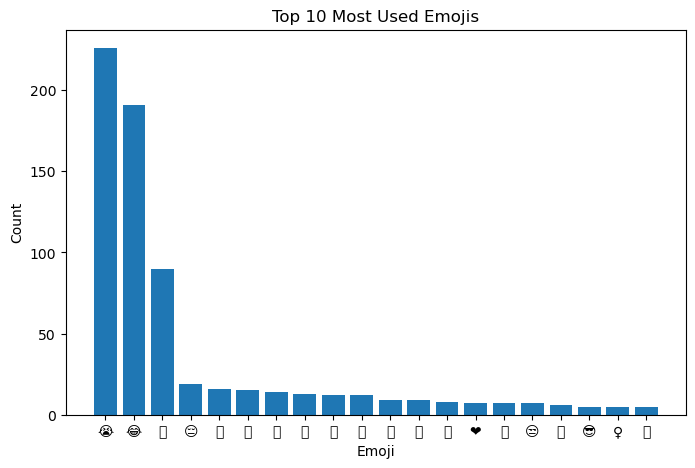

In [28]:
plt.figure(figsize=(8,5))

plt.bar(emoji_df["Emoji"], emoji_df["Count"])

plt.title("Top 10 Most Used Emojis")

plt.xlabel("Emoji")

plt.ylabel("Count")

plt.show()

# Monthly Activity Analysis

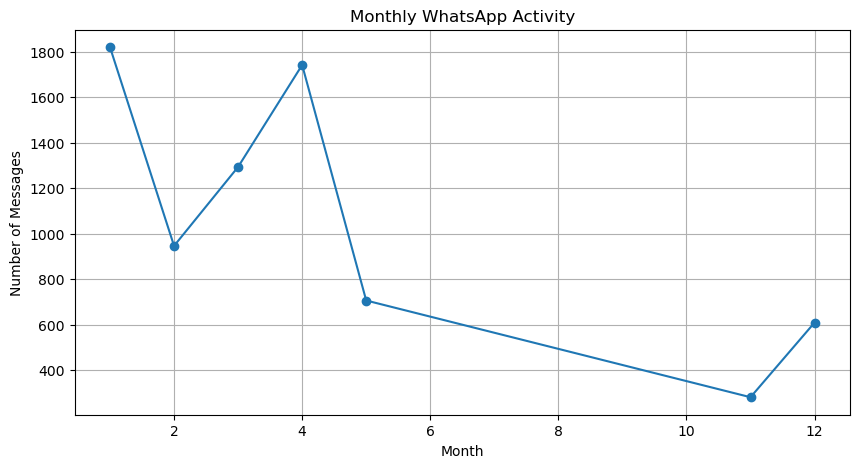

In [29]:
monthly_messages=df.groupby('Month')['Message'].count()
plt.figure(figsize=(10,5))

monthly_messages.plot(
    kind="line",
    marker="o"
)

plt.title("Monthly WhatsApp Activity")
plt.xlabel("Month")
plt.ylabel("Number of Messages")
plt.grid(True)

plt.show()

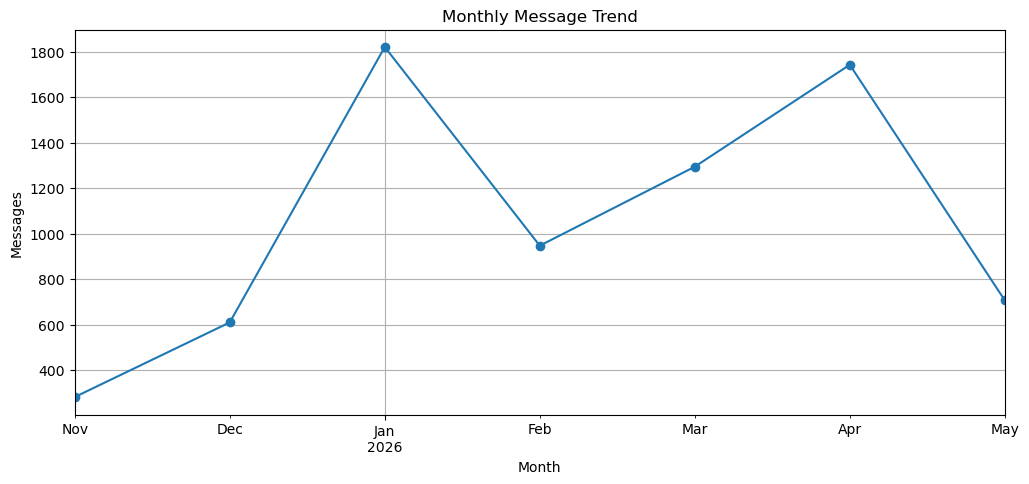

In [30]:
df["YearMonth"] = df["DateTime"].dt.to_period("M")
monthly_trend = df.groupby("YearMonth").size()

plt.figure(figsize=(12,5))

monthly_trend.plot(
    kind="line",
    marker="o"
)

plt.title("Monthly Message Trend")
plt.xlabel("Month")
plt.ylabel("Messages")
plt.grid(True)

plt.show()

# Day v/s Hour

In [31]:
df['DayName']=df['DateTime'].dt.day_name()

df[['DateTime','DayName']].head()

heatmap_data=df.pivot_table(
    index="DayName",
    columns="Hour",
    values="Message",
    aggfunc="count",
    fill_value=0
)

days = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

heatmap_data = heatmap_data.reindex(days)

heatmap_data

Hour,0,1,2,3,5,6,7,8,9,10,...,14,15,16,17,18,19,20,21,22,23
DayName,,,,,,,,,,,,,,,,,,,,,
Monday,52,88,0,1,0,0,9,16,17,53,...,79,12,14,73,71,218,74,56,46,181
Tuesday,18,6,1,0,0,27,73,75,45,222,...,2,18,377,95,165,32,121,79,112,38
Wednesday,2,5,0,0,2,5,1,24,11,93,...,14,28,43,36,81,51,29,32,22,148
Thursday,109,9,0,0,3,5,4,28,145,59,...,6,20,159,25,35,63,108,31,77,156
Friday,3,0,0,0,0,2,8,35,17,127,...,19,48,39,75,82,142,87,156,46,6
Saturday,0,2,0,0,2,0,23,122,49,72,...,12,7,11,49,23,137,65,48,48,80
Sunday,45,4,0,0,0,0,1,1,0,9,...,22,22,16,48,32,29,111,11,78,68


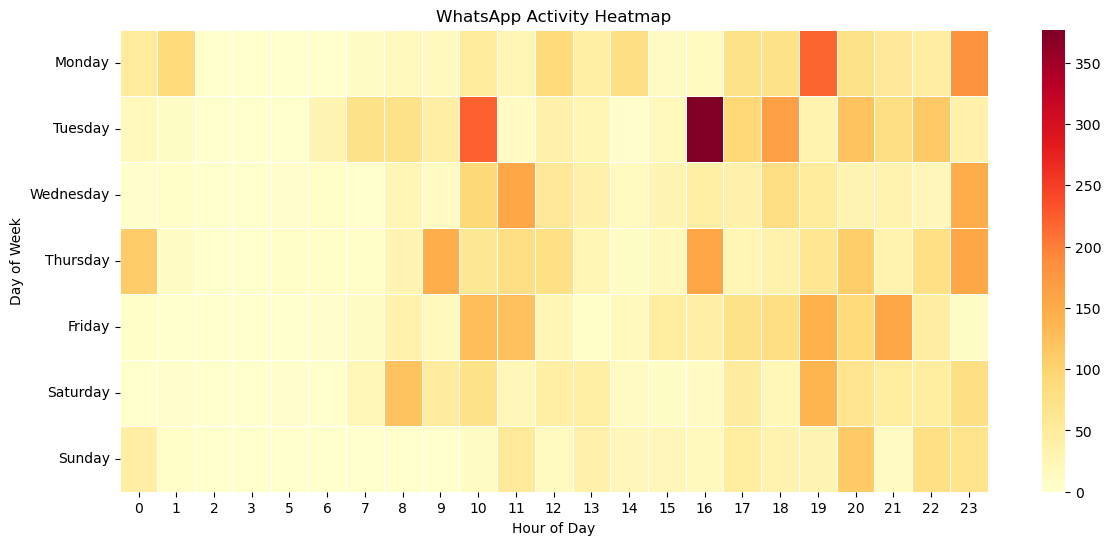

In [32]:
import seaborn as sns

plt.figure(figsize=(14,6))

sns.heatmap(
    heatmap_data,
    cmap="YlOrRd",
    linewidths=0.5
)

plt.title("WhatsApp Activity Heatmap")
plt.xlabel("Hour of Day")
plt.ylabel("Day of Week")

plt.show()

# User Analysis

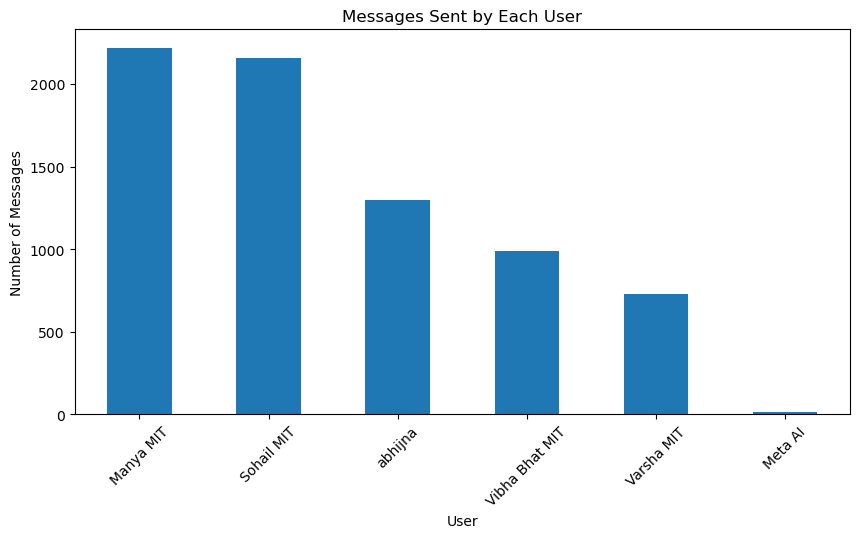

In [33]:
user_messages=df['User'].value_counts()
plt.figure(figsize=(10,5))

user_messages.plot(kind="bar")

plt.title("Messages Sent by Each User")

plt.xlabel("User")

plt.ylabel("Number of Messages")

plt.xticks(rotation=45)

plt.show()

# ***3. Advanced Analytics***

# 3.1 Sentiment Analysis

In [34]:
# here we answer was the conversation positive, negetive or neutral
#Computers can estimate the emotional tone of the text using NLP

# We use TextBlob

!pip install textblob
from textblob import TextBlob

In [35]:
# -1 ------------------ 0 ------------------ +1

#Negative          Neutral             Positive


#0 ------------------- 1

#Fact              Opinion

def get_sentiment(message):
    return TextBlob(message).sentiment.polarity

df['Sentiment']=df['Message'].apply(get_sentiment)

def sentiment_label(score):
    if score >0 :
        return "Positive"
    elif score<0:
        return "negetive"

    else:
        return "Neutral"

df['Sentiment_label']=df['Sentiment'].apply(sentiment_label)

print(df['Sentiment_label'].value_counts())

df[['Message','Sentiment_label','Sentiment']].head(45)

Sentiment_label
Neutral     5921
Positive     973
negetive     508
Name: count, dtype: int64


,Message,Sentiment_label,Sentiment
0,,Neutral,0.0
1,Hey anyone pls send da formula book I have los...,Neutral,0.0
2,<Media omitted>,Neutral,0.0
3,Thankyou,Neutral,0.0
4,<Media omitted>,Neutral,0.0
5,<Media omitted>,Neutral,0.0
6,Sorry bro can't relate,negetive,-0.5
7,Coz I did,Neutral,0.0
8,You guys knew the whole time 😭😭😭,Positive,0.2
9,And no one cared to tell me,Neutral,0.0


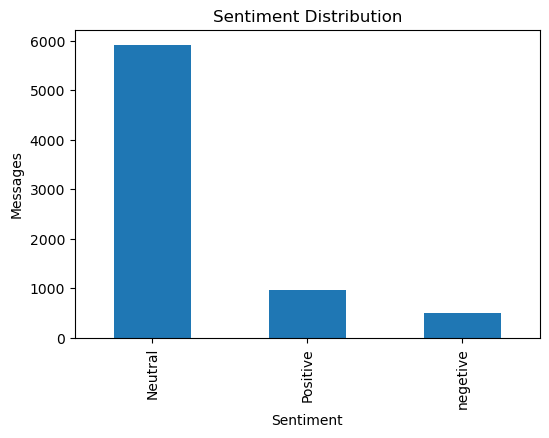

In [36]:
plt.figure(figsize=(6,4))

df["Sentiment_label"].value_counts().plot(kind="bar")

plt.title("Sentiment Distribution")

plt.xlabel("Sentiment")

plt.ylabel("Messages")

plt.show()

In [37]:
#This isa limitaion because textblob woks well for standard english But whatsapp chat
#involves Hinglish and Internet slangs("LOL","LMAO","Bruh")

# Future work: suggesting transformer based multilingual models

# 3.2 Response time Analysis

In [38]:
df= df.sort_values("DateTime").reset_index(drop=True)

df["Previous_User"] = df["Anonymous_User"].shift(1)

df["Previous_Time"] = df["DateTime"].shift(1)

df["Response_Time"] = (
    df["DateTime"] - df["Previous_Time"]
).dt.total_seconds() / 60

reply_df = df[
    df["Anonymous_User"] != df["Previous_User"]
]

reply_df["Response_Time"].mean()

user_response = reply_df.groupby("Anonymous_User")["Response_Time"].mean()

user_response

Anonymous_User
User1    36.068123
User2    52.123679
User3    52.757598
User4    28.532443
User5    31.439239
User6     0.700000
Name: Response_Time, dtype: float64

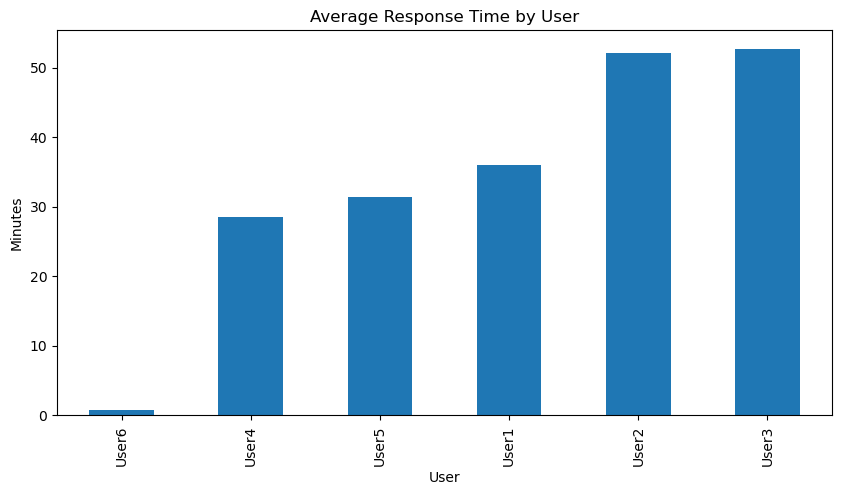

In [39]:
plt.figure(figsize=(10,5))

user_response.sort_values().plot(kind="bar")

plt.title("Average Response Time by User")

plt.xlabel("User")

plt.ylabel("Minutes")

plt.show()